# Workshop 3. EDA, Data Cleaning and Harmonization.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 170)

# The notebook works whether it is launched from the project root or from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = ROOT / "data" / "raw"
PROCESSED_DIR = ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

YEARS = [2015, 2016, 2017, 2018, 2019]
FEATURES = ["gdp", "family", "health", "freedom", "generosity", "corruption"]

## 1. Load the raw files

Each file is read exactly as it is on disk. Note that no file contains a `year` column: the year only exists in the file name.

In [2]:
raw = {year: pd.read_csv(RAW_DIR / f"{year}.csv") for year in YEARS}

for year, df in raw.items():
    print(f"{year}: {df.shape[0]} rows x {df.shape[1]} columns")
    print("   ", list(df.columns))

2015: 158 rows x 12 columns
    ['Country', 'Region', 'Happiness Rank', 'Happiness Score', 'Standard Error', 'Economy (GDP per Capita)', 'Family', 'Health (Life Expectancy)', 'Freedom', 'Trust (Government Corruption)', 'Generosity', 'Dystopia Residual']
2016: 157 rows x 13 columns
    ['Country', 'Region', 'Happiness Rank', 'Happiness Score', 'Lower Confidence Interval', 'Upper Confidence Interval', 'Economy (GDP per Capita)', 'Family', 'Health (Life Expectancy)', 'Freedom', 'Trust (Government Corruption)', 'Generosity', 'Dystopia Residual']
2017: 155 rows x 12 columns
    ['Country', 'Happiness.Rank', 'Happiness.Score', 'Whisker.high', 'Whisker.low', 'Economy..GDP.per.Capita.', 'Family', 'Health..Life.Expectancy.', 'Freedom', 'Generosity', 'Trust..Government.Corruption.', 'Dystopia.Residual']
2018: 156 rows x 9 columns
    ['Overall rank', 'Country or region', 'Score', 'GDP per capita', 'Social support', 'Healthy life expectancy', 'Freedom to make life choices', 'Generosity', 'Percept

## 2. Exploratory Data Analysis

### 2.1 Missing values and duplicated records

In [3]:
def country_column(df):
    return next(c for c in df.columns if c.lower().startswith("country"))

def profile(df):
    return {
        "rows": len(df),
        "columns": df.shape[1],
        "null cells": int(df.isna().sum().sum()),
        "fully duplicated rows": int(df.duplicated().sum()),
        "repeated countries": int(df[country_column(df)].duplicated().sum()),
    }

display(pd.DataFrame({year: profile(df) for year, df in raw.items()}))

print("Rows with missing values:")
for year, df in raw.items():
    rows = df[df.isna().any(axis=1)]
    if len(rows):
        display(rows.assign(year=year))

,2015,2016,2017,2018,2019
rows,158,157,155,156,156
columns,12,13,12,9,9
null cells,0,0,0,1,0
fully duplicated rows,0,0,0,0,0
repeated countries,0,0,0,0,0


Rows with missing values:


,Overall rank,Country or region,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption,year
19,20,United Arab Emirates,6.774,2.096,0.776,0.67,0.284,0.186,NaN,2018


**Observations**

- There are no fully duplicated rows and no repeated countries inside a year.
- There is a single missing value in the whole collection: `Perceptions of corruption` for United Arab Emirates in 2018.

### 2.2 Inconsistent column names and schema differences between years

The same concept is written differently in each file, and some columns exist only in some years. The dictionary below maps every source column to the unified name proposed in section 4. Columns that are not mapped are listed as extra columns.

In [4]:
RENAME = {
    2015: {
        "Country": "country", "Happiness Rank": "happiness_rank", "Happiness Score": "happiness_score",
        "Economy (GDP per Capita)": "gdp", "Family": "family", "Health (Life Expectancy)": "health",
        "Freedom": "freedom", "Trust (Government Corruption)": "corruption", "Generosity": "generosity",
    },
    2017: {
        "Country": "country", "Happiness.Rank": "happiness_rank", "Happiness.Score": "happiness_score",
        "Economy..GDP.per.Capita.": "gdp", "Family": "family", "Health..Life.Expectancy.": "health",
        "Freedom": "freedom", "Trust..Government.Corruption.": "corruption", "Generosity": "generosity",
    },
    2018: {
        "Country or region": "country", "Overall rank": "happiness_rank", "Score": "happiness_score",
        "GDP per capita": "gdp", "Social support": "family", "Healthy life expectancy": "health",
        "Freedom to make life choices": "freedom", "Perceptions of corruption": "corruption",
        "Generosity": "generosity",
    },
}
RENAME[2016] = RENAME[2015]   # 2016 uses the same names as 2015
RENAME[2019] = RENAME[2018]   # 2019 uses the same names as 2018

UNIFIED_ORDER = ["country", "happiness_rank", "happiness_score"] + FEATURES

mapping_table = pd.DataFrame(
    {year: {unified: next(src for src, dst in RENAME[year].items() if dst == unified)
            for unified in UNIFIED_ORDER}
     for year in YEARS}
)
display(mapping_table)

print("Extra columns that exist only in some years (not mapped):")
extra = {year: [c for c in raw[year].columns if c not in RENAME[year]] for year in YEARS}
for year, cols in extra.items():
    print(f"  {year}: {cols}")

,2015,2016,2017,2018,2019
country,Country,Country,Country,Country or region,Country or region
happiness_rank,Happiness Rank,Happiness Rank,Happiness.Rank,Overall rank,Overall rank
happiness_score,Happiness Score,Happiness Score,Happiness.Score,Score,Score
gdp,Economy (GDP per Capita),Economy (GDP per Capita),Economy..GDP.per.Capita.,GDP per capita,GDP per capita
family,Family,Family,Family,Social support,Social support
health,Health (Life Expectancy),Health (Life Expectancy),Health..Life.Expectancy.,Healthy life expectancy,Healthy life expectancy
freedom,Freedom,Freedom,Freedom,Freedom to make life choices,Freedom to make life choices
generosity,Generosity,Generosity,Generosity,Generosity,Generosity
corruption,Trust (Government Corruption),Trust (Government Corruption),Trust..Government.Corruption.,Perceptions of corruption,Perceptions of corruption


Extra columns that exist only in some years (not mapped):
  2015: ['Region', 'Standard Error', 'Dystopia Residual']
  2016: ['Region', 'Lower Confidence Interval', 'Upper Confidence Interval', 'Dystopia Residual']
  2017: ['Whisker.high', 'Whisker.low', 'Dystopia.Residual']
  2018: []
  2019: []


**Observations**

- Three naming conventions for the same variables: spaces and parentheses (2015-2016), dots (2017), and a new vocabulary in 2018-2019 (`Social support`, `Healthy life expectancy`, `Perceptions of corruption`, `Score`, `Overall rank`). Because the extra columns also differ (standard error in 2015, confidence intervals in 2016, whiskers in 2017), there are four different column layouts: 2015, 2016, 2017 and 2018-2019.
- 2017 also changes the column order (`Generosity` comes before `Trust..Government.Corruption.`), so concatenating by position would silently swap two variables.
- `Region` exists only in 2015-2016. `Standard Error` (2015), confidence intervals (2016), whiskers (2017) and `Dystopia Residual` (2015-2017) exist only in some years.
- The six explanatory factors and the score exist in all five years.

### 2.3 Inconsistent data types and numeric precision

In [5]:
renamed = {year: raw[year].rename(columns=RENAME[year]) for year in YEARS}

dtype_table = pd.DataFrame(
    {year: renamed[year][UNIFIED_ORDER].dtypes.astype(str) for year in YEARS}
)
display(dtype_table)

def max_decimals(year, source_column):
    text = pd.read_csv(RAW_DIR / f"{year}.csv", dtype=str)[source_column]
    return int(text.str.split(".").str[1].str.len().max())

score_source = {year: next(s for s, d in RENAME[year].items() if d == "happiness_score") for year in YEARS}
print("Maximum decimals found in the happiness score column:")
for year in YEARS:
    print(f"  {year}: {max_decimals(year, score_source[year])}")

print()
print("Example, first 2017 score as written in the file:",
      pd.read_csv(RAW_DIR / "2017.csv", dtype=str)["Happiness.Score"].iloc[0])

,2015,2016,2017,2018,2019
country,str,str,str,str,str
happiness_rank,int64,int64,int64,int64,int64
happiness_score,float64,float64,float64,float64,float64
gdp,float64,float64,float64,float64,float64
family,float64,float64,float64,float64,float64
health,float64,float64,float64,float64,float64
freedom,float64,float64,float64,float64,float64
generosity,float64,float64,float64,float64,float64
corruption,float64,float64,float64,float64,float64


Maximum decimals found in the happiness score column:
  2015: 3
  2016: 3
  2017: 14
  2018: 3
  2019: 3

Example, first 2017 score as written in the file: 7.53700017929077


**Observations**

- Types are compatible (`int64` for ranks, `float64` for the score and factors, text for countries), so no type conflicts need to be solved.
- Numeric precision is inconsistent: 2015-2016 use 5 decimals for the factors, 2018-2019 use 3, and 2017 carries 14-15 decimals (for example `7.53700017929077`), which is single-precision floating-point noise and not real information.
- The year is not a column in any file and it is derived from the file name.

### 2.4 Country names across years

Which names are not present in all five files?

In [6]:
names = {year: set(renamed[year]["country"]) for year in YEARS}

print("Names with leading/trailing spaces:",
      sum(n != n.strip() for year in YEARS for n in names[year]))

in_all_years = set.intersection(*names.values())
not_in_all = sorted(set.union(*names.values()) - in_all_years)
print(f"Distinct raw names: {len(set.union(*names.values()))} | present in all five years: {len(in_all_years)}")

presence = pd.DataFrame(
    {year: ["yes" if n in names[year] else "" for n in not_in_all] for year in YEARS},
    index=not_in_all,
)
display(presence)

Names with leading/trailing spaces: 0
Distinct raw names: 170 | present in all five years: 141


,2015,2016,2017,2018,2019
Angola,yes,yes,yes,yes,
Belize,,yes,yes,yes,
Central African Republic,yes,,yes,yes,yes
Comoros,yes,yes,,,yes
Djibouti,yes,,,,
Gambia,,,,,yes
Hong Kong,yes,yes,,yes,yes
"Hong Kong S.A.R., China",,,yes,,
Laos,yes,yes,,yes,yes
Lesotho,yes,,yes,yes,yes


Some of these names are the same territory written differently (for example `Hong Kong` in four years and `Hong Kong S.A.R., China` only in 2017). The rest are genuine coverage differences (countries that enter or leave the survey, such as `Gambia`, which appears only in 2019).

A name is treated as a variant only if it is the same place by common knowledge, and the variant and its canonical name never appear in the same year (if both coexisted in one year they would be treated as two different entities).

In [7]:
COUNTRY_MAP = {
    "Hong Kong S.A.R., China": "Hong Kong",
    "Taiwan Province of China": "Taiwan",
    "Trinidad & Tobago": "Trinidad and Tobago",
    "Northern Cyprus": "North Cyprus",
    "Macedonia": "North Macedonia",
    "Somaliland region": "Somaliland Region",
}

rows = []
for variant, canonical in COUNTRY_MAP.items():
    years_variant = [y for y in YEARS if variant in names[y]]
    years_canonical = [y for y in YEARS if canonical in names[y]]
    assert not set(years_variant) & set(years_canonical), (variant, canonical)   # never in the same year
    rows.append({"variant": variant, "years (variant)": years_variant,
                 "canonical": canonical, "years (canonical)": years_canonical})
display(pd.DataFrame(rows))

,variant,years (variant),canonical,years (canonical)
0,"Hong Kong S.A.R., China",[2017],Hong Kong,"[2015, 2016, 2018, 2019]"
1,Taiwan Province of China,[2017],Taiwan,"[2015, 2016, 2018, 2019]"
2,Trinidad & Tobago,"[2018, 2019]",Trinidad and Tobago,"[2015, 2016, 2017]"
3,Northern Cyprus,"[2018, 2019]",North Cyprus,"[2015, 2016, 2017]"
4,Macedonia,"[2015, 2016, 2017, 2018]",North Macedonia,[2019]
5,Somaliland region,[2015],Somaliland Region,[2016]


**Observation:** the six variants are four real renamings (Hong Kong, Taiwan, North Cyprus, North Macedonia) and two formatting differences (`&` vs `and`, and the capital letter of `Somaliland Region`).

### 2.5 Potential outliers and suspicious zeros

,min,max,IQR outliers,exact zeros
gdp,0.000,2.096000,0,5
family,0.000,1.644000,10,5
health,0.000,1.141000,0,5
freedom,0.000,0.724000,0,5
generosity,0.000,0.838075,17,5
corruption,0.000,0.551910,67,6
happiness_score,2.693,7.769000,0,0


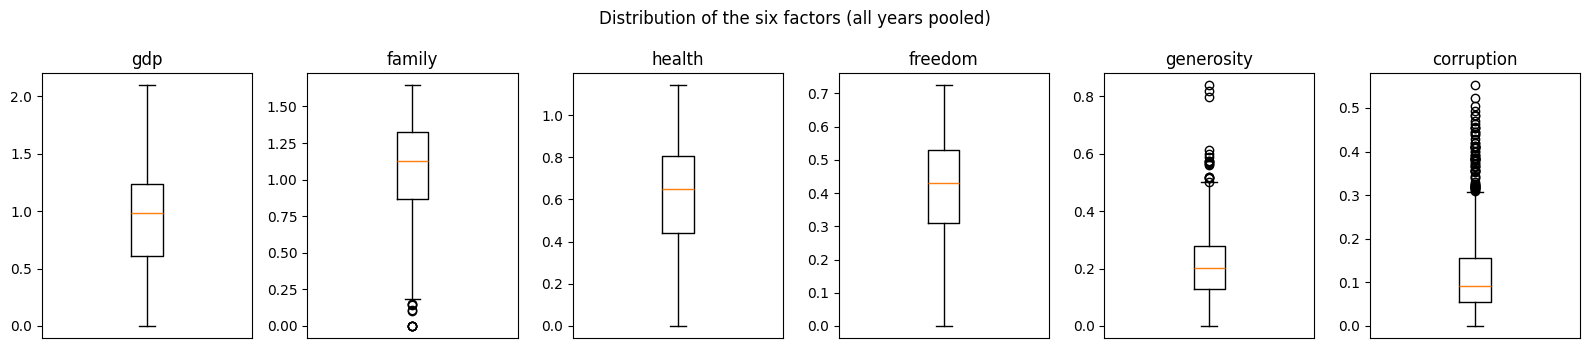

Rows with at least one exact zero in a factor:


,country,happiness_score,gdp,family,health,freedom,generosity,corruption,year
0,Afghanistan,3.203,0.350000,0.517000,0.361000,0.000000,0.158000,0.025000,2019
1,Angola,3.795,0.858428,1.104412,0.049869,0.000000,0.097926,0.069720,2017
2,Angola,3.795,0.730000,1.125000,0.269000,0.000000,0.079000,0.061000,2018
3,Bosnia and Herzegovina,5.163,0.933830,0.643670,0.707660,0.095110,0.298890,0.000000,2016
4,Bosnia and Herzegovina,5.182,0.982409,1.069336,0.705186,0.204403,0.328867,0.000000,2017
5,Bosnia and Herzegovina,5.129,0.915000,1.078000,0.758000,0.280000,0.216000,0.000000,2018
6,Central African Republic,3.678,0.078500,0.000000,0.066990,0.488790,0.238350,0.082890,2015
7,Central African Republic,2.693,0.000000,0.000000,0.018773,0.270842,0.280876,0.056565,2017
8,Central African Republic,3.083,0.024000,0.000000,0.010000,0.305000,0.218000,0.038000,2018
9,Central African Republic,3.083,0.026000,0.000000,0.105000,0.225000,0.235000,0.035000,2019


In [8]:
pooled = pd.concat(
    [renamed[y][["country", "happiness_score"] + FEATURES].assign(year=y) for y in YEARS],
    ignore_index=True,
)

def iqr_outliers(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)).sum())

summary = pd.DataFrame({
    "min": pooled[FEATURES + ["happiness_score"]].min(),
    "max": pooled[FEATURES + ["happiness_score"]].max(),
    "IQR outliers": {c: iqr_outliers(pooled[c]) for c in FEATURES + ["happiness_score"]},
    "exact zeros": (pooled[FEATURES + ["happiness_score"]] == 0).sum(),
})
display(summary)

fig, axes = plt.subplots(1, len(FEATURES), figsize=(16, 3.5))
for ax, col in zip(axes, FEATURES):
    ax.boxplot(pooled[col].dropna())
    ax.set_title(col)
    ax.set_xticks([])
fig.suptitle("Distribution of the six factors (all years pooled)")
plt.tight_layout()
plt.show()

print("Rows with at least one exact zero in a factor:")
display(pooled[(pooled[FEATURES] == 0).any(axis=1)].sort_values(["country", "year"]).reset_index(drop=True))

**Observations**

- No variable has values outside a plausible scale (all factors are between 0 and 2.1, the score between 2.7 and 7.8).
- `corruption` (67), `generosity` (17) and `family` (10) show IQR outliers. They are real, skewed distributions (a few countries with very high perceived trust in government, or very high generosity), not data-entry errors.
- The exact zeros follow a clear pattern: every factor has exactly one zero per year (two in `corruption` 2018), which gives 5 zeros in `gdp`, `family`, `health`, `freedom` and `generosity` and 6 in `corruption`. The zero is the country with the lowest value of that factor in that year (for example Somalia's GDP in 2016, 2018 and 2019, the Central African Republic's social support in four years, or Greece's generosity in all five). This is consistent with factors measured relative to the lowest observed value, so a zero is a property of the index and not a placeholder for missing data.

### 2.6 Which columns would leak the target?

In the World Happiness Report methodology the score is explained as the sum of the six factors plus an unexplained Dystopia Residual. If that identity holds in the files, `Dystopia Residual` is just the target minus the other features and must never be a model input.

In [9]:
dystopia_column = {2015: "Dystopia Residual", 2016: "Dystopia Residual", 2017: "Dystopia.Residual"}

for year, dystopia in dystopia_column.items():
    df = renamed[year]
    gap = (df["happiness_score"] - df[FEATURES].sum(axis=1) - raw[year][dystopia]).abs().max()
    print(f"{year}: max |score - (six factors + dystopia residual)| = {gap:.5f}")

corr_rank = pooled.assign(rank=pd.concat([renamed[y]["happiness_rank"] for y in YEARS], ignore_index=True))[
    ["happiness_score", "rank"]].corr().iloc[0, 1]
print(f"Correlation between happiness_score and happiness_rank: {corr_rank:.3f}")

2015: max |score - (six factors + dystopia residual)| = 0.00051
2016: max |score - (six factors + dystopia residual)| = 0.00050
2017: max |score - (six factors + dystopia residual)| = 0.00050
Correlation between happiness_score and happiness_rank: -0.992


**Observation:** the identity holds up to rounding (about 0.0005) in 2015, 2016 and 2017. Therefore:

- `Dystopia Residual` is a direct leakage of the target and exists only in three of five years.
- `Happiness Rank` is a deterministic function of the score inside each year (strong negative correlation), so it is also leakage.
- `Standard Error`, confidence intervals and whiskers are derived from the score estimate and are absent in several years.

## 3. Data quality observations (summary)

| # | Dimension | Observation | Decision |
|---|---|---|---|
| 1 | Completeness | 1 missing value in 782 rows: `corruption` of United Arab Emirates, 2018 | Impute from the same country's neighbouring years |
| 2 | Uniqueness | No duplicated rows and no repeated country inside a year | Keep a uniqueness check as a post-cleaning assertion |
| 3 | Naming consistency | Three naming conventions for the same variables (four column layouts in total); 2017 also reorders columns | Rename explicitly per year |
| 4 | Schema consistency | `Region`, `Standard Error`, confidence intervals, whiskers and `Dystopia Residual` exist only in some years | Keep only the columns common to all years |
| 5 | Type / precision consistency | 2017 stores 14-15 decimals of floating-point noise; year is not a column | Round to 5 decimals; derive `year` from the file name |
| 6 | Entity consistency | 6 country names are variants of the same territory (170 raw names, 164 real countries) | Explicit `COUNTRY_MAP`, verified so that variant and canonical never coexist in a year |
| 7 | Validity / outliers | IQR outliers in `corruption`, `generosity`, `family`; exactly one zero per factor and year (the lowest country of that factor) | Keep them: they are real values of the index, not errors |
| 8 | Leakage risk | `Dystopia Residual` and `Happiness Rank` are derived from the target | Exclude from the features |

## 4. Unified schema proposal

| Column | Type | Description | Source in each year |
|---|---|---|---|
| `country` | string | Harmonized country name | `Country` / `Country or region` |
| `year` | int | Observation year | derived from the file name |
| `happiness_rank` | int | Rank of the country inside its year | `Happiness Rank` / `Happiness.Rank` / `Overall rank` |
| `happiness_score` | float | **Target** of the regression model | `Happiness Score` / `Happiness.Score` / `Score` |
| `gdp` | float | Economy (GDP per capita) contribution | `Economy (GDP per Capita)` / `GDP per capita` |
| `family` | float | Family / social support contribution | `Family` / `Social support` |
| `health` | float | Health (life expectancy) contribution | `Health (Life Expectancy)` / `Healthy life expectancy` |
| `freedom` | float | Freedom contribution | `Freedom` / `Freedom to make life choices` |
| `generosity` | float | Generosity contribution | `Generosity` |
| `corruption` | float | Perception of corruption / trust in government contribution | `Trust (Government Corruption)` / `Perceptions of corruption` |

The names `gdp`, `family`, `health`, `freedom`, `generosity` and `corruption` are the same names used by the event contract so that a streamed event and a training row speak the same language.

Uniqueness rule of the schema: one row per (`country`, `year`).

## 5. Cleaning and harmonization pipeline

In [10]:
def harmonize(year, df):
    """Return one year of data expressed in the unified schema."""
    out = df.rename(columns=RENAME[year])[UNIFIED_ORDER].copy()   # explicit names, never by position
    out.insert(1, "year", year)                                    # year comes from the file name
    out["country"] = out["country"].str.strip().replace(COUNTRY_MAP)
    out["happiness_rank"] = out["happiness_rank"].astype("int64")
    out["year"] = out["year"].astype("int64")
    for col in ["happiness_score"] + FEATURES:
        out[col] = out[col].astype("float64").round(5)             # removes the 2017 floating-point noise
    return out

unified = pd.concat([harmonize(y, raw[y]) for y in YEARS], ignore_index=True)
print("Rows after merging the five years:", len(unified))

Rows after merging the five years: 782


In [11]:
# Precision check: rounding must not change a single value of the years that were already clean.
for year in (2015, 2016, 2018, 2019):
    source = raw[year].rename(columns=RENAME[year])
    for col in FEATURES:
        assert np.allclose(source[col].dropna().round(5).values,
                           source[col].dropna().values, atol=0, rtol=0), (year, col)
print("Rounding to 5 decimals only affects the 2017 file.")

Rounding to 5 decimals only affects the 2017 file.


In [12]:
# Missing value: United Arab Emirates 2018 -> mean of the same country's previous and next year.
missing = unified[unified[FEATURES].isna().any(axis=1)]
display(missing)

for idx, row in missing.iterrows():
    for col in FEATURES:
        if pd.isna(row[col]):
            neighbours = unified[(unified["country"] == row["country"])
                                 & (unified["year"].isin([row["year"] - 1, row["year"] + 1]))][col]
            assert neighbours.notna().sum() == 2, "both neighbouring years are required for this rule"
            unified.loc[idx, col] = round(neighbours.mean(), 5)
            print(f"Imputed {col} for {row['country']} {row['year']}: "
                  f"mean of {neighbours.round(5).tolist()} = {unified.loc[idx, col]}")

,country,year,happiness_rank,happiness_score,gdp,family,health,freedom,generosity,corruption
489,United Arab Emirates,2018,20,6.774,2.096,0.776,0.67,0.284,0.186,NaN


Imputed corruption for United Arab Emirates 2018: mean of [0.32449, 0.182] = 0.25324


In [13]:
unified = unified.sort_values(["year", "happiness_rank"]).reset_index(drop=True)
unified

,country,year,happiness_rank,happiness_score,gdp,family,health,freedom,generosity,corruption
0,Switzerland,2015,1,7.587,1.39651,1.34951,0.94143,0.66557,0.29678,0.41978
1,Iceland,2015,2,7.561,1.30232,1.40223,0.94784,0.62877,0.43630,0.14145
2,Denmark,2015,3,7.527,1.32548,1.36058,0.87464,0.64938,0.34139,0.48357
3,Norway,2015,4,7.522,1.45900,1.33095,0.88521,0.66973,0.34699,0.36503
4,Canada,2015,5,7.427,1.32629,1.32261,0.90563,0.63297,0.45811,0.32957
...,...,...,...,...,...,...,...,...,...,...
777,Rwanda,2019,152,3.334,0.35900,0.71100,0.61400,0.55500,0.21700,0.41100
778,Tanzania,2019,153,3.231,0.47600,0.88500,0.49900,0.41700,0.27600,0.14700
779,Afghanistan,2019,154,3.203,0.35000,0.51700,0.36100,0.00000,0.15800,0.02500
780,Central African Republic,2019,155,3.083,0.02600,0.00000,0.10500,0.22500,0.23500,0.03500


### Post-cleaning verification

The cleaned dataset must satisfy the unified schema. These assertions turn the data quality observations into checks that fail loudly if the pipeline is ever re-run on different data.

In [14]:
expected_rows = {year: len(raw[year]) for year in YEARS}

assert unified.shape[0] == sum(expected_rows.values()), "rows were lost or created"
assert unified.groupby("year").size().to_dict() == expected_rows, "per-year row counts changed"
assert unified.isna().sum().sum() == 0, "there are still missing values"
assert not unified.duplicated(["country", "year"]).any(), "a country appears twice in the same year"
assert not unified.duplicated().any(), "duplicated rows"
assert (unified[FEATURES] >= 0).all().all(), "negative factor"
assert unified["happiness_score"].between(0, 10).all(), "score outside the 0-10 scale"
assert all(variant not in set(unified["country"]) for variant in COUNTRY_MAP), "a country variant survived"
assert unified["country"].eq(unified["country"].str.strip()).all(), "whitespace in country names"
assert list(unified.columns) == ["country", "year", "happiness_rank", "happiness_score"] + FEATURES

print("All checks passed.\n")
print(unified.dtypes.to_string())
print()
countries_per_year = unified.groupby("country")["year"].nunique().value_counts().sort_index(ascending=False)
print(f"Distinct countries: {unified['country'].nunique()}")
print("Number of countries by number of years observed:")
print(countries_per_year.to_string())

All checks passed.

country                str
year                 int64
happiness_rank       int64
happiness_score    float64
gdp                float64
family             float64
health             float64
freedom            float64
generosity         float64
corruption         float64

Distinct countries: 164
Number of countries by number of years observed:
year
5    146
4      9
3      2
2      3
1      4


In [15]:
display(unified.groupby("year")[["happiness_score"] + FEATURES].mean().round(3))

,happiness_score,gdp,family,health,freedom,generosity,corruption
year,,,,,,,
2015,5.376,0.846,0.991,0.630,0.429,0.237,0.143
2016,5.382,0.954,0.794,0.558,0.371,0.243,0.138
2017,5.354,0.985,1.189,0.551,0.409,0.247,0.123
2018,5.376,0.891,1.213,0.597,0.455,0.181,0.113
2019,5.407,0.905,1.209,0.725,0.393,0.185,0.111


The yearly means are stable (the score stays around 5.35-5.41 and no factor changes scale between years), so the five files can be pooled without rescaling.

## 6. Justification of the cleaning decisions

| Decision | Why | Alternative rejected |
|---|---|---|
| Rename columns with an explicit per-year dictionary and select by name | 2017 reorders columns; positional concatenation would silently mix `generosity` and `corruption` | Concatenate by position |
| Keep only the columns common to all five years | A model and a streaming event contract can only rely on fields that always exist | Keep `Region`, `Standard Error`, intervals, whiskers (missing in 2-4 years, would create artificial nulls) |
| Drop `Dystopia Residual`, `Happiness Rank`, `Standard Error`, intervals and whiskers from the modelling schema | They are derived from the target | Keep them: would give an unrealistically good model that fails in streaming, where they do not exist |
| Derive `year` from the file name | No file contains it; without it a country's five observations cannot be told apart | Infer from row order |
| Harmonize 6 country-name variants with an explicit, verified dictionary | Variants split one territory in two; verifying that variant and canonical never coexist in a year proves they are the same entity | Fuzzy string matching (can merge different countries) |
| Do not fill or force the countries that are absent in some years | Their absence is real survey coverage (for example `Gambia`, `Somalia`, `Belize`); inventing rows would create fake observations | Reindex to a complete country-by-year grid |
| Impute the single missing `corruption` value with the mean of the same country's previous and next year | Keeps the record (782 rows instead of 781), uses only values already in the dataset, and the series for that country is smooth and monotonic (0.386, 0.356, 0.324, ?, 0.182) so the average of the neighbours is a defensible estimate | Drop the row (loses a valid observation), global median (ignores that corruption perception is country specific) |
| Round factors and score to 5 decimals | Removes the 2017 single-precision noise and gives every year the same precision; verified not to change any 2015-2016-2018-2019 value | Keep raw floats (identical values would differ in the 12th decimal across years) |
| Keep outliers and exact zeros | They are real values of a skewed index and not errors (each zero is the lowest country of that factor in that year); removing them would bias the model against the most extreme countries | Winsorize or delete rows |
| Do not rescale in the cleaning step | The five yearly distributions share the same scale; scaling is a learned transformation and belongs in the model pipeline, so it can be reproduced identically in streaming | Standardize here (would leak test-set statistics into training) |

## 7. Save the unified dataset

In [16]:
output_path = PROCESSED_DIR / "happiness_unified.csv"
unified.to_csv(output_path, index=False)

check = pd.read_csv(output_path)
assert check.shape == unified.shape and list(check.columns) == list(unified.columns)
print(f"Saved {len(check)} rows to {output_path.relative_to(ROOT)}")
check.head()

Saved 782 rows to data/processed/happiness_unified.csv


,country,year,happiness_rank,happiness_score,gdp,family,health,freedom,generosity,corruption
0,Switzerland,2015,1,7.587,1.39651,1.34951,0.94143,0.66557,0.29678,0.41978
1,Iceland,2015,2,7.561,1.30232,1.40223,0.94784,0.62877,0.43630,0.14145
2,Denmark,2015,3,7.527,1.32548,1.36058,0.87464,0.64938,0.34139,0.48357
3,Norway,2015,4,7.522,1.45900,1.33095,0.88521,0.66973,0.34699,0.36503
4,Canada,2015,5,7.427,1.32629,1.32261,0.90563,0.63297,0.45811,0.32957
